# UMAP, densMAP, PaCMAP, LocalMAP and ForceAtlas2

*Python port of the R vignettes [UMAP](https://gregorlueg.github.io/manifoldsR/articles/umap.html), [densMAP and den-SNE](https://gregorlueg.github.io/manifoldsR/articles/density_preserving.html), [PaCMAP](https://gregorlueg.github.io/manifoldsR/articles/pacmap.html) and [ForceAtlas2](https://gregorlueg.github.io/manifoldsR/articles/fa2.html). Original author: Gregor Lueg.*

The graph layout family. [UMAP](https://arxiv.org/abs/1802.03426) and its
density-preserving sibling
[densMAP](https://www.nature.com/articles/s41587-020-00801-7),
[PaCMAP](https://arxiv.org/abs/2012.04456) and its locally adjusted
successor [LocalMAP](https://arxiv.org/abs/2412.15426), and Gephi's
[ForceAtlas2](https://doi.org/10.1371/journal.pone.0098679). All of them
start from a kNN graph and pull neighbours together while pushing everything
else apart. Where they differ is in what they push and when.

In [1]:
import time
import warnings

# umap-learn's spectral init on the disconnected cluster graph and tqdm in a
# headless kernel both warn; neither matters here. Set before the imports, which
# is when tqdm warns.
warnings.filterwarnings("ignore", message="Graph is not fully connected")
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import pacmap
import polars as pl
import umap
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr
from sklearn.decomposition import PCA

import manifolds_rs as mf

pl.Config.set_fmt_str_lengths(60)


def scatter(
    ax: plt.Axes, emb: np.ndarray, c: np.ndarray, title: str, cmap: str = "tab10"
) -> None:
    """One embedding, coloured by `c`, without axis ticks."""
    ax.scatter(emb[:, 0], emb[:, 1], c=c, s=1, cmap=cmap, alpha=0.6)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


def panels(
    embeddings: dict[str, np.ndarray], c: np.ndarray, cmap: str = "tab10"
) -> None:
    """A row of embeddings sharing one colouring."""
    fig, axes = plt.subplots(
        1, len(embeddings), figsize=(4.3 * len(embeddings), 4.3), squeeze=False
    )
    for ax, (name, emb) in zip(axes[0], embeddings.items(), strict=True):
        scatter(ax, emb, c, name, cmap)
    fig.tight_layout()


def timed(fn) -> float:
    """Wall time of one call, in seconds."""
    start = time.perf_counter()
    fn()
    return time.perf_counter() - start

## UMAP

UMAP builds a weighted kNN graph in the input space, where the edge weights
say how likely two points are to be connected under a local, adaptive metric
(the [kNN vignette](../knn_searches/) has the searches). It then minimises
the cross-entropy between that graph and its low-dimensional twin, pulling
connected points together and pushing unconnected ones apart. That is why
**UMAP is great at clusters**: if two points are unlikely neighbours, the
repulsion drives them apart and you get clean separation.

The flip side: UMAP has **no incentive to keep relative distances along a
continuum**. On trajectory-like data the loss treats weakly connected distant
points as things to repel, not as part of one structure, and continuous
manifolds get torn into spurious clusters.
[UMAP is a visualisation tool, not a metric space!](https://journals.plos.org/ploscompbiol/article?id=10.1371/journal.pcbi.1011288)

The default optimiser is a parallel Adam, the same idea as `uwot::umap2()`.
Each node gathers its gradient and takes its Adam step in one pass, in
parallel, so it scales with your cores and the same seed gives the same
embedding every time.

In [2]:
X_clust, y_clust = mf.datasets.clustered(25_000)
X_swiss, t_swiss = mf.datasets.swiss_roll(1_000)
X_traj, y_traj = mf.datasets.trajectory(25_000)
order = np.random.default_rng(42).permutation(len(y_traj))

### Clustered data, swiss roll and trajectory

PCA against UMAP on all three. The trajectory points are shuffled before
plotting so the later branches don't hide the earlier ones.

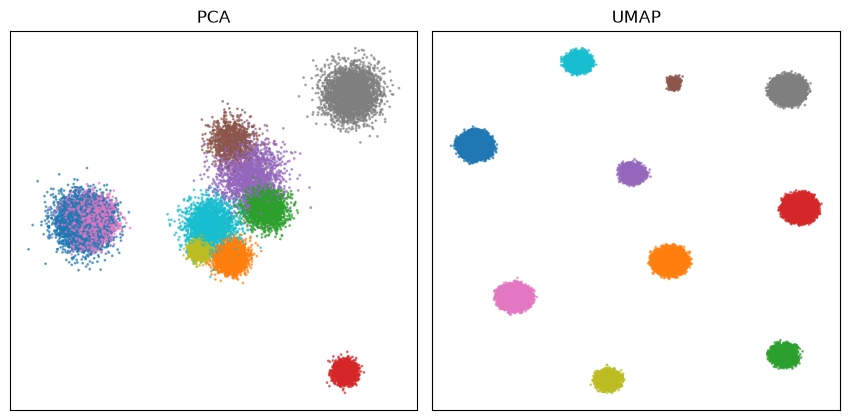

In [3]:
panels(
    {
        "PCA": PCA(2).fit_transform(X_clust),
        "UMAP": mf.UMAP().fit_transform(X_clust),
    },
    y_clust,
)

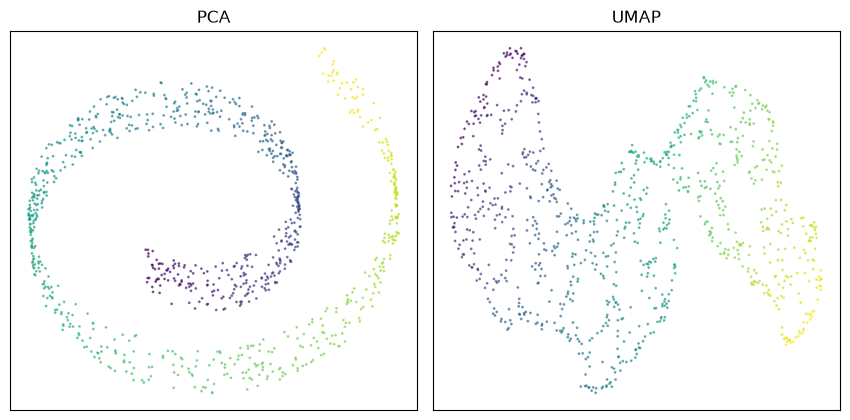

In [4]:
panels(
    {
        "PCA": PCA(2).fit_transform(X_swiss),
        "UMAP": mf.UMAP(ann="exhaustive").fit_transform(X_swiss),
    },
    t_swiss,
    cmap="viridis",
)

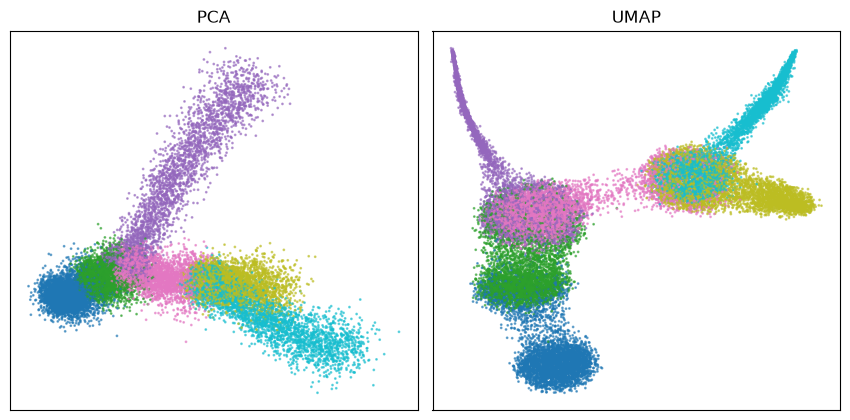

In [5]:
panels(
    {
        "PCA": PCA(2).fit_transform(X_traj)[order],
        "UMAP": mf.UMAP().fit_transform(X_traj)[order],
    },
    y_traj[order],
)

Clusters: UMAP pulls apart what PCA leaves overlapping. Swiss roll and
trajectory: PCA shows you the continuum, UMAP breaks it into pieces with some
bleeding in between. Pick the algorithm for the structure you expect.

### Pre-computed kNN graphs

Sweeping `min_dist` with the neighbours fixed? Build the graph once and pass
it to `fit_transform`.

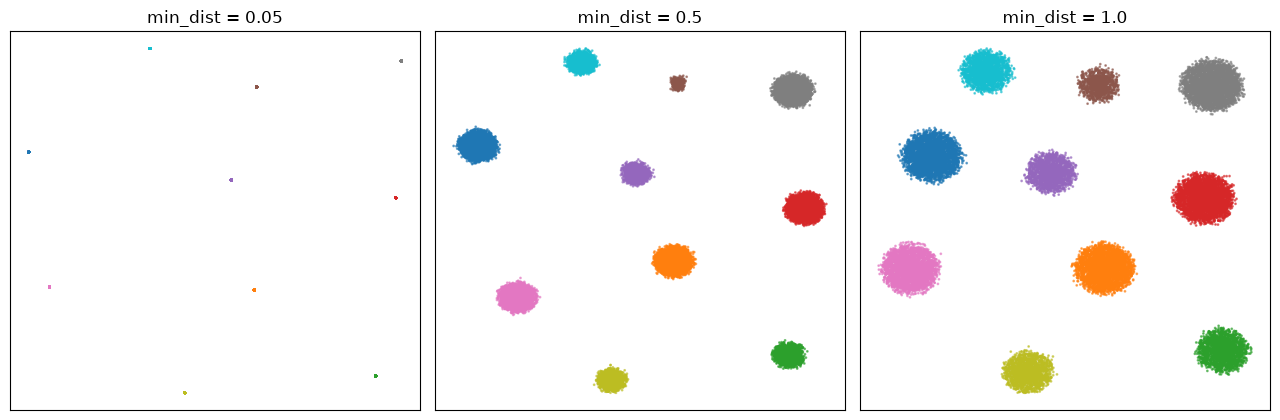

In [6]:
idx15, dist15 = mf.knn_graph(X_clust, k=15, ann="nndescent")

panels(
    {
        f"min_dist = {md}": mf.UMAP(min_dist=md).fit_transform(
            X_clust, knn_indices=idx15, knn_distances=dist15
        )
        for md in (0.05, 0.5, 1.0)
    },
    y_clust,
)

### Optimisers

Five of them:

- `"adam_parallel"` (default): parallel Adam, reproducible.
- `"adam"`: the same Adam, single-threaded.
- `"sgd"`: the classic umap-learn and `uwot::umap()` SGD with edge sampling.
  Single-threaded, reproducible.
- `"sgd_parallel"`: the same SGD lock-free,
  [Hogwild!](https://arxiv.org/abs/1106.5730) style. All threads write to the
  embedding without locks, which is where the speed comes from. The price:
  with more than one thread it is **not reproducible** run to run, seed or
  no seed.
- `"adam_v06"`: the Adam of umap-learn 0.6, with its own learning rate
  schedule. Pair it with `init="recursive"`, the umap-learn 0.6 label
  propagation initialisation, and it takes the short warm-up umap-learn uses
  for a good start.

Like umap-learn, the SGD optimisers drop to 200 epochs above 10k samples
unless you set `n_epochs`.

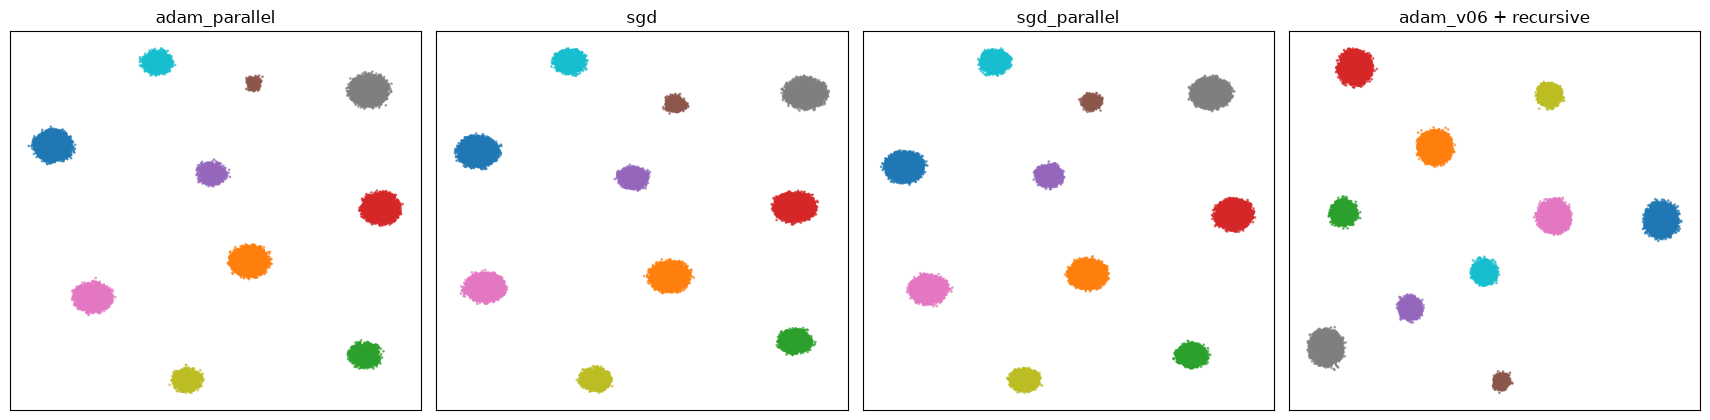

In [7]:
optimisers = {
    "adam_parallel": mf.UMAP(),
    "sgd": mf.UMAP(optimiser="sgd"),
    "sgd_parallel": mf.UMAP(optimiser="sgd_parallel"),
    "adam_v06 + recursive": mf.UMAP(optimiser="adam_v06", init="recursive"),
}
panels(
    {
        name: est.fit_transform(X_clust, knn_indices=idx15, knn_distances=dist15)
        for name, est in optimisers.items()
    },
    y_clust,
)

Same clusters four times. The 0.6 Adam with the recursive start lands on a
different arrangement, which is the initialisation talking, not the
optimiser. On reproducibility, don't take my word for it:

In [8]:
{
    name: np.array_equal(
        mf.UMAP(optimiser=name).fit_transform(
            X_clust, knn_indices=idx15, knn_distances=dist15
        ),
        mf.UMAP(optimiser=name).fit_transform(
            X_clust, knn_indices=idx15, knn_distances=dist15
        ),
    )
    for name in ("adam_parallel", "sgd_parallel")
}

{'adam_parallel': True, 'sgd_parallel': False}

## densMAP

Cluster sizes in a UMAP mean nothing. A blob twice as wide as its neighbour
might be ten times tighter in the input, because nothing in the loss cares
how spread out a neighbourhood was. densMAP adds one term:

$$-\lambda \cdot \mathrm{Corr}(\log R_o, \log R_e)$$

$R_o$ is a local radius in the input, a graph-weighted average squared
distance to a point's neighbours, and $R_e$ the matching radius in the
embedding. Maximise the correlation and a tight cluster stays tight, a
diffuse one diffuse. Same graph, same repulsion, same optimisers otherwise.
The knobs:

- `lambda_`: weight of the density term, `2.0` by default. `0` gives plain
  UMAP back.
- `DensParams(frac=...)`: fraction of the epochs, at the end, over which the
  term runs. `0.3` by default; switching it on from epoch zero fights the
  initialisation. Over the last 30% only, so you pay maybe a third more
  wall time.
- `DensParams(var_shift=...)`: a shift on the variance of the embedding
  log-radii that keeps the correlation sane when the radii collapse.

The umap-learn 0.6 Adam has no density term, so densMAP refuses
`"adam_v06"`.

To see any of this we need local density before and after. A proxy for
$R_o$: the log of the mean squared distance to the 15 nearest neighbours.

method,rho
str,f64
"""UMAP""",0.011
"""densMAP""",0.921


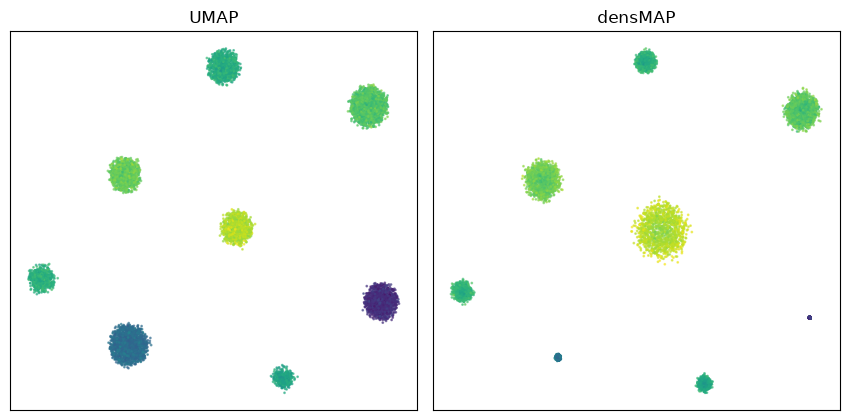

In [9]:
def local_radii(x: np.ndarray, k: int = 15) -> np.ndarray:
    """Log mean squared distance to the `k` nearest neighbours, per point."""
    _, d = mf.knn_graph(x, k=k, ann="kmknn")
    return np.log((d.astype(np.float64) ** 2).mean(axis=1) + 1e-8)


def dens_cor(radii: np.ndarray, emb: np.ndarray) -> float:
    """Spearman correlation of input and embedding local radii."""
    return round(float(spearmanr(radii, local_radii(emb)).statistic), 3)


X_dens, y_dens = mf.datasets.clustered(10_000, n_clusters=8)
radii = local_radii(X_dens)

dens = {
    "UMAP": mf.UMAP().fit_transform(X_dens),
    "densMAP": mf.DensMAP().fit_transform(X_dens),
}
panels(dens, radii, cmap="viridis")
pl.DataFrame({"method": list(dens), "rho": [dens_cor(radii, e) for e in dens.values()]})

Coloured by the *input* radius. UMAP hands you clusters of roughly equal size
whatever the colour. densMAP lets the diffuse ones sprawl and squeezes the
tight ones, and the Spearman correlation `rho` puts a number on it.

`lambda_=0` is plain UMAP, bit for bit. A handy sanity check, and the
cheapest way to A/B the thing:

In [10]:
np.array_equal(mf.DensMAP(lambda_=0.0).fit_transform(X_dens), dens["UMAP"])

True

### Density along a manifold

Clusters are the easy case. The biased swiss roll samples non-uniformly along
the roll, so the density gradient is continuous rather than blocky.

method,rho
str,f64
"""UMAP""",0.16
"""densMAP""",0.785


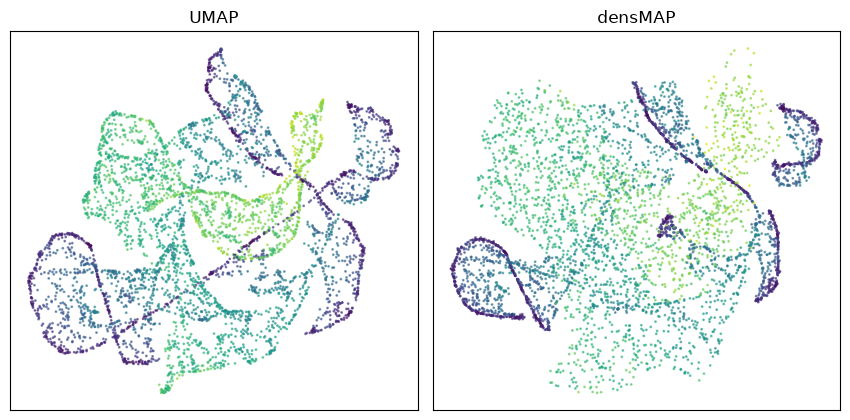

In [11]:
X_bias, _ = mf.datasets.swiss_roll(5_000, noise=0.1, density_bias=2.5)
radii_bias = local_radii(X_bias)

bias = {
    "UMAP": mf.UMAP(ann="exhaustive").fit_transform(X_bias),
    "densMAP": mf.DensMAP(ann="exhaustive").fit_transform(X_bias),
}
panels(bias, radii_bias, cmap="viridis")
pl.DataFrame(
    {"method": list(bias), "rho": [dens_cor(radii_bias, e) for e in bias.values()]}
)

### Tuning lambda

The usual framing is that `lambda_` trades cluster separation for density
fidelity. Let's check on 2000 points. Separation here is the mean distance
between cluster centroids over the mean distance of a point to its own
centroid.

In [12]:
def separation(emb: np.ndarray, labels: np.ndarray) -> float:
    """Mean centroid distance over mean within-cluster distance to the centroid."""
    ids = np.unique(labels)
    cent = np.stack([emb[labels == g].mean(axis=0) for g in ids])
    within = np.mean(
        [
            np.linalg.norm(emb[labels == g] - cent[i], axis=1).mean()
            for i, g in enumerate(ids)
        ]
    )
    return float(pdist(cent).mean() / within)


X_small, y_small = mf.datasets.clustered(2_000, n_clusters=8)
radii_small = local_radii(X_small)
idx_small, dist_small = mf.knn_graph(X_small, k=15)

rows = []
for lam in (0.0, 0.5, 2.0, 5.0, 10.0):
    emb = mf.DensMAP(lambda_=lam).fit_transform(
        X_small, knn_indices=idx_small, knn_distances=dist_small
    )
    rows.append(
        {
            "lambda": lam,
            "rho": dens_cor(radii_small, emb),
            "separation": round(separation(emb, y_small), 2),
        }
    )
pl.DataFrame(rows)

lambda,rho,separation
f64,f64,f64
0.0,0.04,28.69
0.5,0.891,36.81
2.0,0.935,35.75
5.0,0.942,32.1
10.0,0.947,28.13


Not quite what the framing promises. Nearly all the fidelity arrives by
`lambda_ = 0.5` and barely moves after. Separation *improves* over plain UMAP
the moment the density term switches on, peaks early and then erodes slowly;
only at `10` does it drop back to the `0` baseline. So on this data the
trade-off only bites well past the default. Well-separated blobs are the
friendly case, so sweep on your own data, but `2.0` sits on the flat part of
both curves and is a sane start.

## PaCMAP

PaCMAP builds its embedding from three kinds of pair. **Near pairs** keep
local neighbourhoods. **Mid-near pairs**, the second closest of six random
points, are a medium-range pull that anchors the global structure.
**Further pairs**, random distant points minus the near pairs, push.

The trick is the **phased schedule**. In phase one the mid-near weight decays
from 1000 to 3, which pulls points into a globally coherent arrangement
before any local structure is resolved. In phase two it holds at 3 while the
near weight rises, so local structure emerges without wrecking the layout.
Phase three runs on near and further pairs only. UMAP optimises one objective
from the start; PaCMAP settles the global picture first.

Three things to know:

- **PCA initialisation.** Random init throws away most of the global
  structure, hence `init="pca"` by default.
- **`n_near` is less touchy than UMAP's `n_neighbors`.** The paper's 10 works
  across a wide range of data. The search runs `n_near + 50` wide and the near
  pairs are the best of those by locally scaled distance, so a pre-computed
  graph should be `n_near + 50` wide too.
- **Mid-near pairs don't come from the graph.** They are sampled.

## LocalMAP

LocalMAP is PaCMAP with a different phase three. Further pairs that already
sit more than `max_distance` apart in the embedding get resampled (they have
done their job), and the near-pair forces are scaled by their embedding
distance. The upshot: clusters PaCMAP leaves touching get pulled apart, and
the global arrangement from the first two phases stays. Same arguments as
PaCMAP, plus `max_distance` (default 10).

The hierarchical data is where the difference between UMAP and the PaCMAP
family shows. 16 subclusters in 4 supergroups, in 50 dimensions.

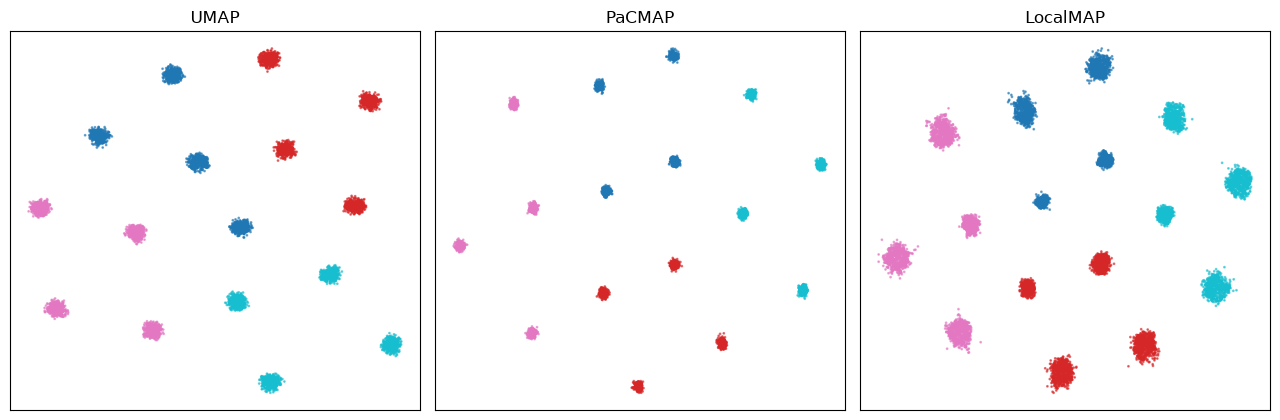

In [13]:
X_hier, supergroup, subgroup = mf.datasets.hierarchical(10_000, n_subclusters=4)

hier = {
    "UMAP": mf.UMAP().fit_transform(X_hier),
    "PaCMAP": mf.PaCMAP().fit_transform(X_hier),
    "LocalMAP": mf.LocalMAP().fit_transform(X_hier),
}
panels(hier, supergroup)

Coloured by supergroup. Two numbers per embedding: the Spearman correlation of
subcluster centroid distances, input against embedding (global), and the
fraction of each point's 15 nearest neighbours that survive (local).

In [14]:
def global_preservation(x: np.ndarray, emb: np.ndarray, groups: np.ndarray) -> float:
    """Spearman correlation of group centroid distances, input vs embedding."""
    ids = np.unique(groups)
    cx = np.stack([x[groups == g].mean(axis=0) for g in ids])
    ce = np.stack([emb[groups == g].mean(axis=0) for g in ids])
    return float(spearmanr(pdist(cx), pdist(ce)).statistic)


def knn_preservation(x: np.ndarray, emb: np.ndarray, k: int = 15) -> float:
    """Mean fraction of each point's `k` exact neighbours kept in the embedding."""
    a, _ = mf.knn_graph(x, k=k, ann="exhaustive")
    b, _ = mf.knn_graph(emb, k=k, ann="exhaustive")
    return sum(len(set(i) & set(j)) for i, j in zip(a, b, strict=True)) / a.size


pl.DataFrame(
    {
        "method": list(hier),
        "global": [global_preservation(X_hier, e, subgroup) for e in hier.values()],
        "local": [knn_preservation(X_hier, e) for e in hier.values()],
        "separation": [separation(e, subgroup) for e in hier.values()],
    }
).with_columns(pl.exclude("method").round(3))

method,global,local,separation
str,f64,f64,f64
"""UMAP""",0.553,0.048,43.898
"""PaCMAP""",0.729,0.049,91.266
"""LocalMAP""",0.715,0.077,25.182


`separation` is the score from the densMAP section, over the 16 subclusters.

PaCMAP places the supergroups better than UMAP (global) and squeezes every
subcluster into a dot, hence its huge separation score. LocalMAP keeps the
global placement and gives the subclusters their internal spread back: more
of each point's neighbours survive (local), and the subclusters get bigger
relative to the gaps, so its separation score drops. Don't read the score as
"worse": dots are easy to separate and tell you nothing about what is inside
them.

PaCMAP and LocalMAP on the other two datasets:

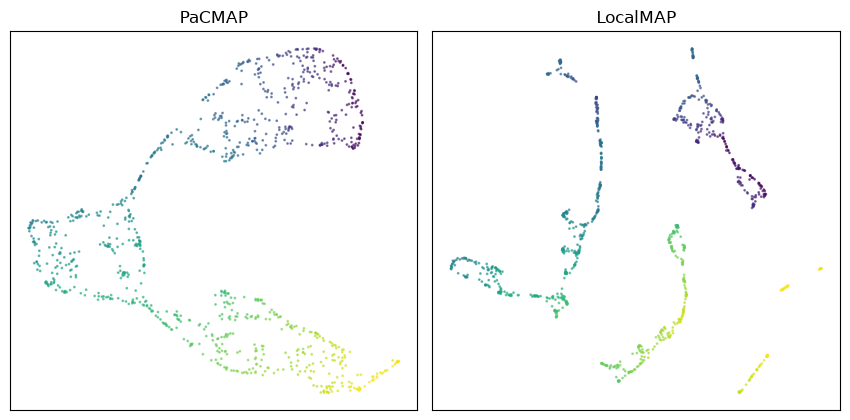

In [15]:
panels(
    {
        "PaCMAP": mf.PaCMAP().fit_transform(X_swiss),
        "LocalMAP": mf.LocalMAP().fit_transform(X_swiss),
    },
    t_swiss,
    cmap="viridis",
)

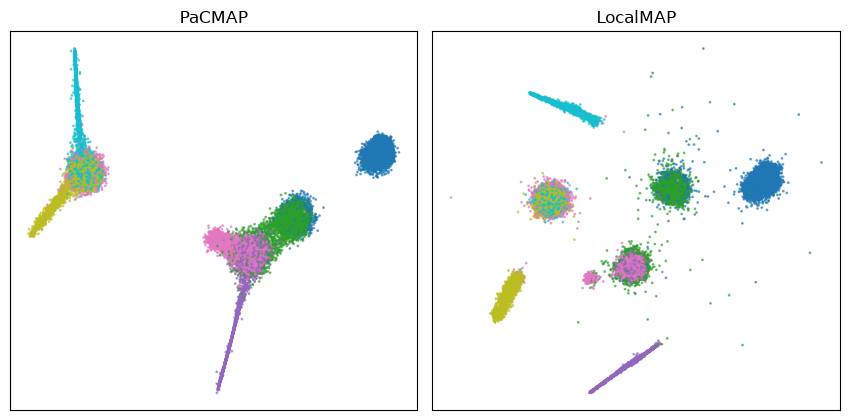

In [16]:
panels(
    {
        "PaCMAP": mf.PaCMAP().fit_transform(X_traj)[order],
        "LocalMAP": mf.LocalMAP().fit_transform(X_traj)[order],
    },
    y_traj[order],
)

On the swiss roll both keep the gradient along the roll. On the trajectory
LocalMAP does what it was built for and pulls apart what touches, which on a
continuum means tearing the branches into islands. The reference `pacmap`
implementation of LocalMAP does the same on this data. For trajectories stay
with PaCMAP, or better, PHATE.

### Pre-computed kNN and the phase schedule

With the graph fixed you can play with the schedule. Here phase one runs to
epoch 300 instead of 100, so the mid-near pairs dominate for much longer.

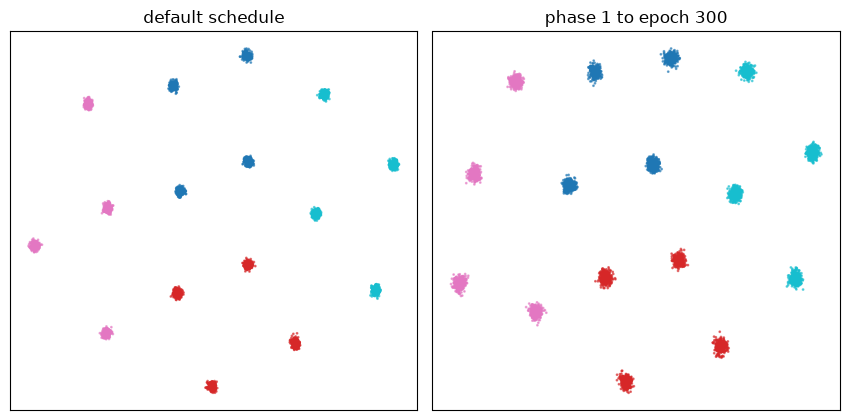

In [17]:
idx60, dist60 = mf.knn_graph(X_hier, k=60, ann="ivf")

panels(
    {
        "default schedule": mf.PaCMAP().fit_transform(
            X_hier, knn_indices=idx60, knn_distances=dist60
        ),
        "phase 1 to epoch 300": mf.PaCMAP(
            optim_params=mf.PacmapOptim(phase1_end=300, phase2_end=400)
        ).fit_transform(X_hier, knn_indices=idx60, knn_distances=dist60),
    },
    supergroup,
)

## ForceAtlas2

Gephi's force-directed layout, known in single cell from scanpy's
`draw_graph` and PAGA-initialised layouts. ForceAtlas2 treats the graph as a
physical system. Every node repels every other with a force of `1/d`, scaled
by the node masses (`1 + degree`, so hubs push harder). Every edge pulls its
ends together, linearly with distance or logarithmically with `lin_log=True`.
Gravity pulls everything to the origin so disconnected components don't
drift off. Step sizes follow Gephi's adaptive speed, and the all-pairs
repulsion runs on a Barnes-Hut tree.

How is that different from UMAP? UMAP samples edges and negatives and
minimises a loss. ForceAtlas2 visits every edge every epoch and has no loss,
just forces. No `min_dist` or `spread` either: the scale of the layout falls
out of `scaling_ratio` (repulsion) against the edge weights (attraction). It
runs on the same fuzzy union graph UMAP builds, as scanpy does, and needs it
symmetric, so `UmapGraph(mix_weight=...)` has to stay at 1.

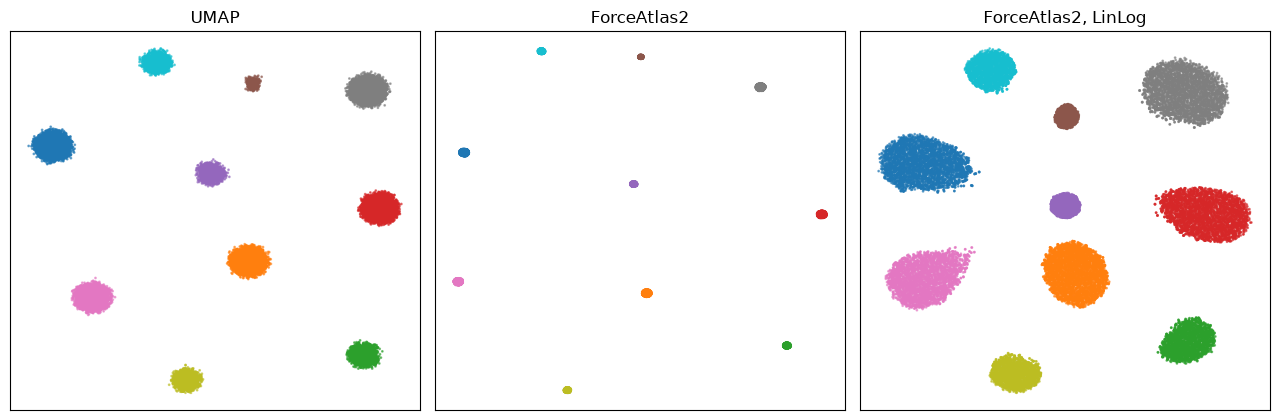

In [18]:
panels(
    {
        "UMAP": mf.UMAP().fit_transform(
            X_clust, knn_indices=idx15, knn_distances=dist15
        ),
        "ForceAtlas2": mf.ForceAtlas2().fit_transform(
            X_clust, knn_indices=idx15, knn_distances=dist15
        ),
        "ForceAtlas2, LinLog": mf.ForceAtlas2(lin_log=True).fit_transform(
            X_clust, knn_indices=idx15, knn_distances=dist15
        ),
    },
    y_clust,
)

Same global arrangement as UMAP, since both start from the same spectral
initialisation. With linear attraction and a dense within-cluster graph,
ForceAtlas2 crushes each cluster into a tight blob. LinLog's logarithmic
attraction grows much slower with distance, so the clusters open up again.
The coordinates live on Gephi's scale, so tens of thousands are normal; only
the relative positions mean anything.

Trajectories are where force-directed layouts get used most in single cell.

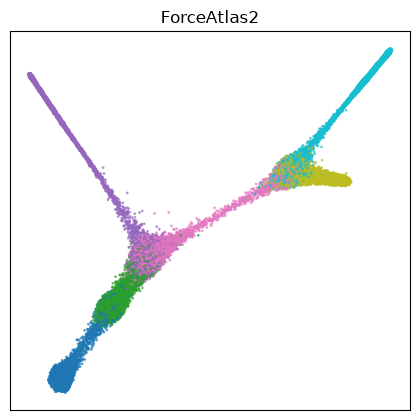

In [19]:
panels(
    {"ForceAtlas2": mf.ForceAtlas2().fit_transform(X_traj)[order]},
    y_traj[order],
)

The knobs worth knowing: `scaling_ratio` (repulsion, bigger spreads
everything), `gravity` (raise it if small components float away, lower it if
everything gets squashed into a ball), `lin_log`, `n_epochs` (no learning
rate to anneal, so more epochs is a more settled layout), and
`Fa2Optim(dissuade_hubs=True)`, which pushes hubs to the edge of their
community. Leave `theta` and `jitter_tolerance` alone unless you know why
you're touching them.

## Benchmarks

Against [umap-learn](https://github.com/lmcinnes/umap) 0.6 and the reference
[PaCMAP](https://github.com/YingfanWang/PaCMAP) package (which also ships
LocalMAP), on all cores. One run each, wall time in seconds, neighbour search
included. Both references compile with numba on first use, so they get a
warm-up call on a small dataset before the clock starts.

Like for like where it exists: umap-learn's default 0.6 path (recursive init
and Adam) against our `"adam_v06"` with `init="recursive"`, and its legacy
SGD layout against our `"sgd_parallel"`, which is equally non-reproducible.

In [20]:
X_warm, _ = mf.datasets.clustered(2_000)
umap.UMAP(optimizer="adam").fit_transform(X_warm)
umap.UMAP(compatibility_layout=True).fit_transform(X_warm)
pacmap.PaCMAP().fit_transform(X_warm)
pacmap.LocalMAP().fit_transform(X_warm)


def bench(x: np.ndarray) -> pl.DataFrame:
    """Wall time of our UMAP, PaCMAP and LocalMAP and the references on `x`."""
    runs = {
        "manifolds-rs UMAP adam_parallel": lambda: mf.UMAP().fit_transform(x),
        "manifolds-rs UMAP adam_v06 + recursive": lambda: mf.UMAP(
            optimiser="adam_v06", init="recursive"
        ).fit_transform(x),
        "umap-learn adam + recursive": lambda: umap.UMAP(
            optimizer="adam"
        ).fit_transform(x),
        "manifolds-rs UMAP sgd_parallel": lambda: mf.UMAP(
            optimiser="sgd_parallel"
        ).fit_transform(x),
        "umap-learn sgd": lambda: umap.UMAP(compatibility_layout=True).fit_transform(x),
        "manifolds-rs PaCMAP": lambda: mf.PaCMAP().fit_transform(x),
        "pacmap PaCMAP": lambda: pacmap.PaCMAP().fit_transform(x),
        "manifolds-rs LocalMAP": lambda: mf.LocalMAP().fit_transform(x),
        "pacmap LocalMAP": lambda: pacmap.LocalMAP().fit_transform(x),
    }
    return pl.DataFrame(
        [{"method": k, "seconds": timed(fn)} for k, fn in runs.items()]
    ).with_columns(pl.col("seconds").round(2))


bench(mf.datasets.clustered(50_000)[0])

method,seconds
str,f64
"""manifolds-rs UMAP adam_parallel""",2.1
"""manifolds-rs UMAP adam_v06 + recursive""",2.72
"""umap-learn adam + recursive""",22.13
"""manifolds-rs UMAP sgd_parallel""",1.58
"""umap-learn sgd""",4.61
"""manifolds-rs PaCMAP""",0.88
"""pacmap PaCMAP""",6.39
"""manifolds-rs LocalMAP""",1.24
"""pacmap LocalMAP""",7.03


UMAP: against umap-learn's 0.6 default (recursive init plus Adam), our port
of the same thing is several times faster, and our default parallel Adam a
little faster still. On the legacy SGD the gap is smaller, but still there.
PaCMAP and LocalMAP: a fraction of the reference package's time.